# 00 · Baseline models (Kaggle Playground S6E10: Predicting Airline Satisfaction)

**Goal:** predict the probability that a passenger is satisfied. **Score:** ROC AUC (higher is better, 1.0 = perfect).

This notebook gives the team a starting point:
1. Load and clean the data with the shared `src/clean.py`
2. Three baseline models on the team's fixed validation split
3. Confusion matrix for the best model
4. Kaggle-ready submission files
5. Where our scores would rank on the final leaderboard

In [1]:
import sys, time
sys.path.append('..')          # so we can import src/ from the notebooks folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, recall_score, accuracy_score

from src.clean import load_data, make_features, make_split, save_submission

## 1. Load the data

In [2]:
train, test = load_data()
print('train:', train.shape, ' test:', test.shape)
print('share satisfied:', round(train['satisfaction'].mean(), 4))
train.head()

train: (699635, 23)  test: (299844, 22)
share satisfied: 0.4436


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


## 2. Leaderboard, for comparison
Final private leaderboard downloaded 2026-11-26 (`report/leaderboard_private_2026-11-26.csv`).

In [3]:
lb = pd.read_csv('../report/leaderboard_private_2026-11-26.csv')
lb = lb[lb['Score'] > 0.5]            # drop a few broken submissions
def rank(auc):
    return int((lb['Score'] > auc).sum()) + 1
print('teams:', len(lb), ' best:', lb['Score'].max(), ' median:', round(lb['Score'].median(), 5))

teams: 3715  best: 0.96318  median: 0.96081


## 3. Baseline models
All three use the **same** validation split from `make_split` so scores can be compared.

In [4]:
results = {}

# A. Logistic regression, ratings treated as numbers 0-5
X, y, X_test = make_features(train, test, ratings_as_categories=False)
X_tr, X_va, y_tr, y_va = make_split(X, y)
scaler = StandardScaler().fit(X_tr)
lr_a = LogisticRegression(max_iter=2000).fit(scaler.transform(X_tr), y_tr)
results['A: logistic, ratings as numbers'] = roc_auc_score(y_va, lr_a.predict_proba(scaler.transform(X_va))[:, 1])

# B. Logistic regression, ratings one-hot encoded (0 = 'not applicable' is its own category)
Xb, yb, Xb_test = make_features(train, test, ratings_as_categories=True)
Xb_tr, Xb_va, yb_tr, yb_va = make_split(Xb, yb)
scaler_b = StandardScaler().fit(Xb_tr)
lr_b = LogisticRegression(max_iter=3000).fit(scaler_b.transform(Xb_tr), yb_tr)
p_b = lr_b.predict_proba(scaler_b.transform(Xb_va))[:, 1]
results['B: logistic, ratings one-hot'] = roc_auc_score(yb_va, p_b)

# C. Gradient-boosted trees (an ensemble of small decision trees)
t = time.time()
hgb = HistGradientBoostingClassifier(max_iter=2000, learning_rate=0.05, max_leaf_nodes=63,
                                     early_stopping=True, n_iter_no_change=50, random_state=0)
hgb.fit(X_tr, y_tr)
p_c = hgb.predict_proba(X_va)[:, 1]
results['C: gradient boosting'] = roc_auc_score(y_va, p_c)
print(f'boosting took {time.time()-t:.0f}s, {hgb.n_iter_} trees')

table = pd.DataFrame({'validation AUC': results}).round(5)
table['would rank'] = [f'{rank(a):,} / {len(lb):,}' for a in table['validation AUC']]
table

boosting took 28s, 398 trees


,validation AUC,would rank
"A: logistic, ratings as numbers",0.92064,"3,669 / 3,715"
"B: logistic, ratings one-hot",0.94767,"3,535 / 3,715"
C: gradient boosting,0.95758,"3,364 / 3,715"


## 4. Confusion matrix (model C, threshold 0.5)
Rows = real answer, columns = prediction. Positive = satisfied.

In [5]:
pred = (p_c >= 0.5).astype(int)
cm = confusion_matrix(y_va, pred)          # (y_true, y_pred): rows are the real class
tn, fp, fn, tp = cm.ravel()
print(pd.DataFrame(cm, index=['real: not satisfied', 'real: satisfied'],
                   columns=['pred: not satisfied', 'pred: satisfied']))
print(f'accuracy {accuracy_score(y_va, pred):.4f} · precision {precision_score(y_va, pred):.4f} · recall {recall_score(y_va, pred):.4f}')

                     pred: not satisfied  pred: satisfied
real: not satisfied                73464             4395
real: satisfied                     6144            55924
accuracy 0.9247 · precision 0.9271 · recall 0.9010


## 5. Chart: our scores vs the leaderboard (saved for the report)

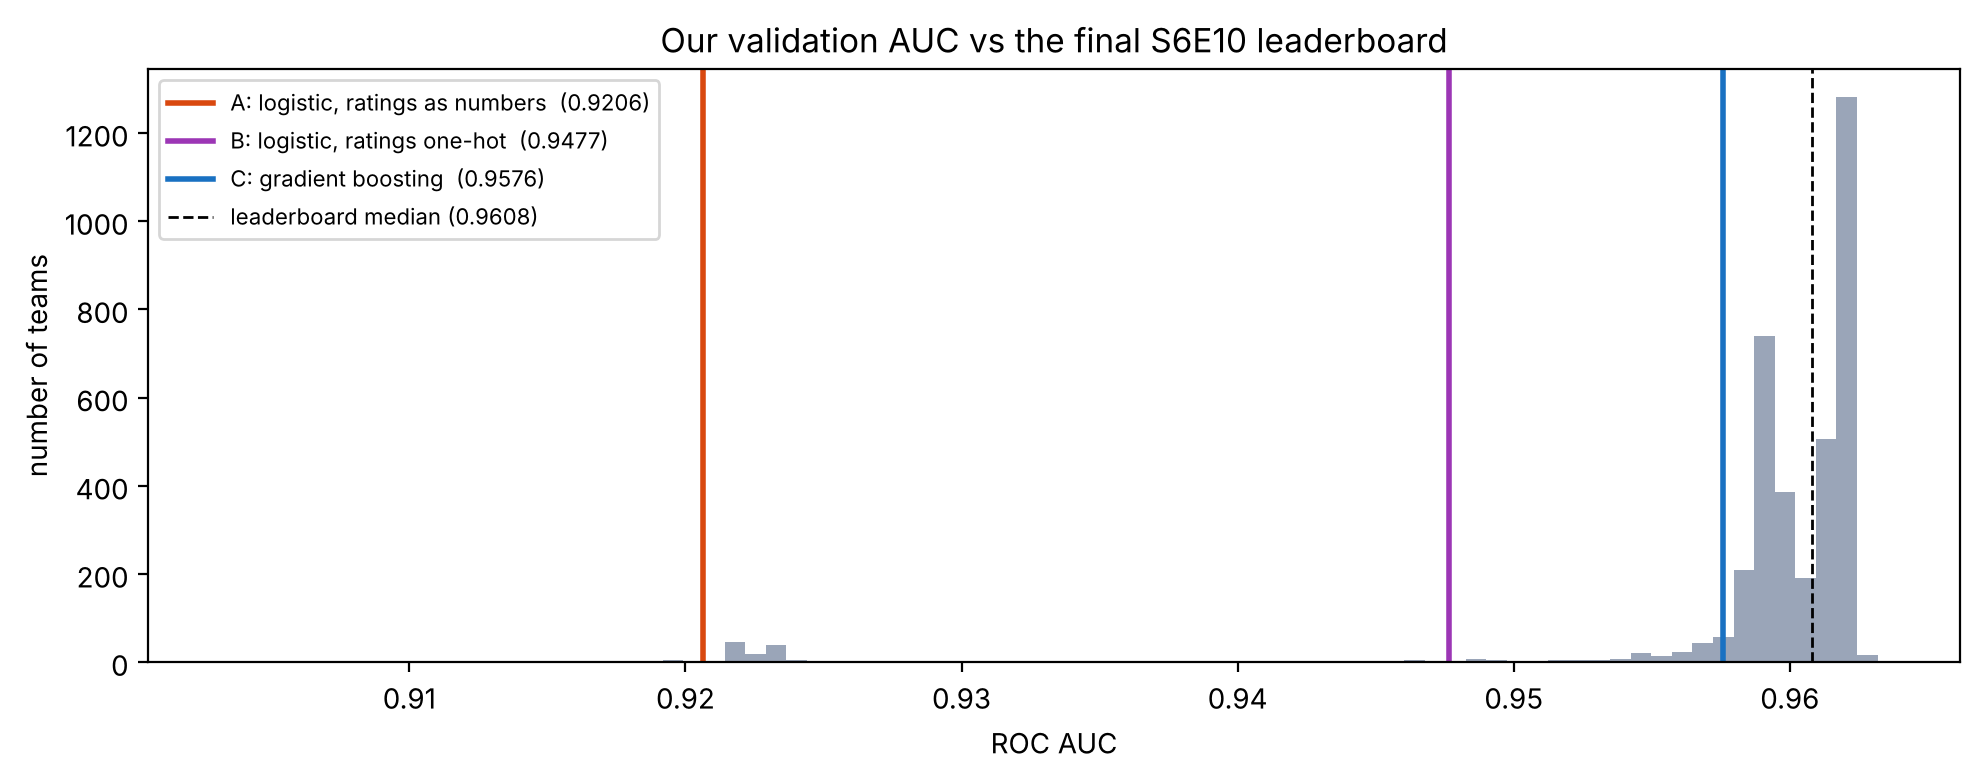

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(lb['Score'][lb['Score'] > 0.90], bins=80, color='#9aa5b8')
for (name, auc), c in zip(results.items(), ['#d9480f', '#9c36b5', '#1971c2']):
    ax.axvline(auc, color=c, lw=2, label=f'{name}  ({auc:.4f})')
ax.axvline(lb['Score'].median(), color='black', ls='--', lw=1, label=f"leaderboard median ({lb['Score'].median():.4f})")
ax.set_xlabel('ROC AUC'); ax.set_ylabel('number of teams')
ax.set_title('Our validation AUC vs the final S6E10 leaderboard')
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.savefig('../report/figures/baseline_vs_leaderboard.png', dpi=150)
plt.show()

## 6. Submission files
Refit each model on **all** training rows, then predict probabilities for the test set.
Upload a file from `submissions/` with **Late Submission** on Kaggle, then log the score in the README.

In [7]:
scaler_full = StandardScaler().fit(Xb)
lr_full = LogisticRegression(max_iter=3000).fit(scaler_full.transform(Xb), yb)
print(save_submission(test, lr_full.predict_proba(scaler_full.transform(Xb_test))[:, 1], 'baseline_logreg_onehot'))

hgb_full = HistGradientBoostingClassifier(max_iter=hgb.n_iter_, learning_rate=0.05, max_leaf_nodes=63,
                                          early_stopping=False, random_state=0).fit(X, y)
print(save_submission(test, hgb_full.predict_proba(X_test)[:, 1], 'baseline_gradient_boosting'))

saved submissions/baseline_logreg_onehot.csv


saved submissions/baseline_gradient_boosting.csv


## What this tells us
* **Cleaning matters:** treating the 0-5 ratings as categories (0 = not applicable) lifted logistic regression a lot.
* **Trees beat a straight line** here, but the top of the leaderboard is very tight. Small AUC gains move rank a lot.
* Next ideas: tune boosting, a random forest, extra features (total delay, average rating), averaging models.